# CIFAR ResNet under five million parameters
Pengxiao Yu - Deep Learning Project 1, Fall 2026.

This notebook executes code and loads the saved experiment. Validation accuracy is separate from the hidden Kaggle score. No pretrained weights are used. See README for data download and full training commands.

AI assistance: OpenAI Codex assisted implementation, experiment orchestration and report drafting.

In [1]:
from pathlib import Path
import sys, json, torch
ROOT = Path.cwd()
if not (ROOT / 'code/model.py').exists():
    raise RuntimeError('Run this notebook from the repository root')
sys.path.insert(0, str(ROOT / 'code'))
from model import CifarResNet, parameter_count
from checks import main as run_checks
print(json.dumps(run_checks(), indent=2))
model = CifarResNet(width=40)
print(f'Trainable parameters: {parameter_count(model):,}')
assert parameter_count(model) <= 5_000_000
print('Random initialization; no pretrained checkpoint downloaded.')

{
  "parameters": 4368690,
  "budget_pass": true,
  "residual_identity_pass": true,
  "finite_gradients_pass": true,
  "checkpoint_roundtrip_pass": true,
  "augmentation_no_cross_image_mix_pass": true,
  "synthetic_only": true
}
Trainable parameters: 4,368,690
Random initialization; no pretrained checkpoint downloaded.


In [2]:
manifest = json.loads((ROOT/'data/manifest.json').read_text())
print(json.dumps(manifest, indent=2))
summary = json.loads((ROOT/'results/main/summary.json').read_text())
assert summary['complete'] is True
assert summary['epochs_completed'] == 80
print(json.dumps(summary, indent=2))
print(f"Fixed-split validation accuracy: {100*summary['validation']['accuracy']:.2f}%")
score_file = ROOT/'results/main/kaggle_result.json'
if score_file.exists():
    kaggle = json.loads(score_file.read_text())
    assert kaggle['verified_from_ui'] is True
    score_label = kaggle.get('score_label', 'Kaggle leaderboard test accuracy')
    print(f"{score_label}: {100*float(kaggle['score']):.2f}%")
    print('A public leaderboard score describes its scored subset; private-test accuracy requires separate verification.')
    print('Kaggle record:', kaggle.get('url', 'See verification artifact'))
else:
    print('Hidden competition test accuracy: not yet verified; validation accuracy is separate.')

{
  "source": "Instructor Brightspace announcement Nov 1 2026; identical to Kaggle per announcement",
  "zip_sha256": "397e06e5752bfe0576d1258765bbe1d020cca02db2fc21442cbab6d50257ca51",
  "train_shape": [
    50000,
    32,
    32,
    3
  ],
  "test_shape": [
    2000,
    32,
    32,
    3
  ],
  "class_counts": [
    5000,
    5000,
    5000,
    5000,
    5000,
    5000,
    5000,
    5000,
    5000,
    5000
  ],
  "split_seed": 2026,
  "train_count": 45000,
  "val_count": 5000,
  "train_indices_sha256": "7ec888cd36bd8133aeac8b0e5e4640d924a9279cc339e953754720039a344d44",
  "val_indices_sha256": "ac709c8440322e7870d2d23251d354b94456cf990704ac86c6bd6124ce0f118a",
  "npz_sha256": "26415c9dcadaac912e019034377bc5e41a2a2dba35b3b479fdc2e6cc287a6790"
}
{
  "complete": true,
  "best_epoch": 77,
  "validation": {
    "loss": 0.2063811511993408,
    "accuracy": 0.951,
    "correct": 4755,
    "count": 5000
  },
  "parameters": 4368690,
  "elapsed_seconds": 3638.231567162962,
  "epochs_comple

In [3]:
# Re-execute inference from the selected checkpoint, preserving sample CSV order.
import subprocess
inference_device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('Inference device:', inference_device)
cmd = [sys.executable, 'code/predict.py', '--device', inference_device]
proc = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, check=True)
print(proc.stdout)
assert (ROOT/'results/main/submission.csv').exists()
print('Submission CSV generated from executed checkpoint inference.')

Inference device: mps


{
  "checkpoint_sha256": "8a9b66c1b3a49e899b9a05b8b5ed9f78898f90fda708b8fc0099816ca08d66a1",
  "submission_sha256": "99372484f170abb603a332d753ab8d62e58c726bb745389cd71a05caa94d6413",
  "rows": 2000,
  "parameters": 4368690,
  "validation_recheck": {
    "loss": 0.2063811511993408,
    "accuracy": 0.951,
    "correct": 4755,
    "count": 5000
  },
  "tta": false,
  "test_accuracy": null,
  "note": "CSV predictions only. Hidden test accuracy is verified separately on Kaggle."
}

Submission CSV generated from executed checkpoint inference.


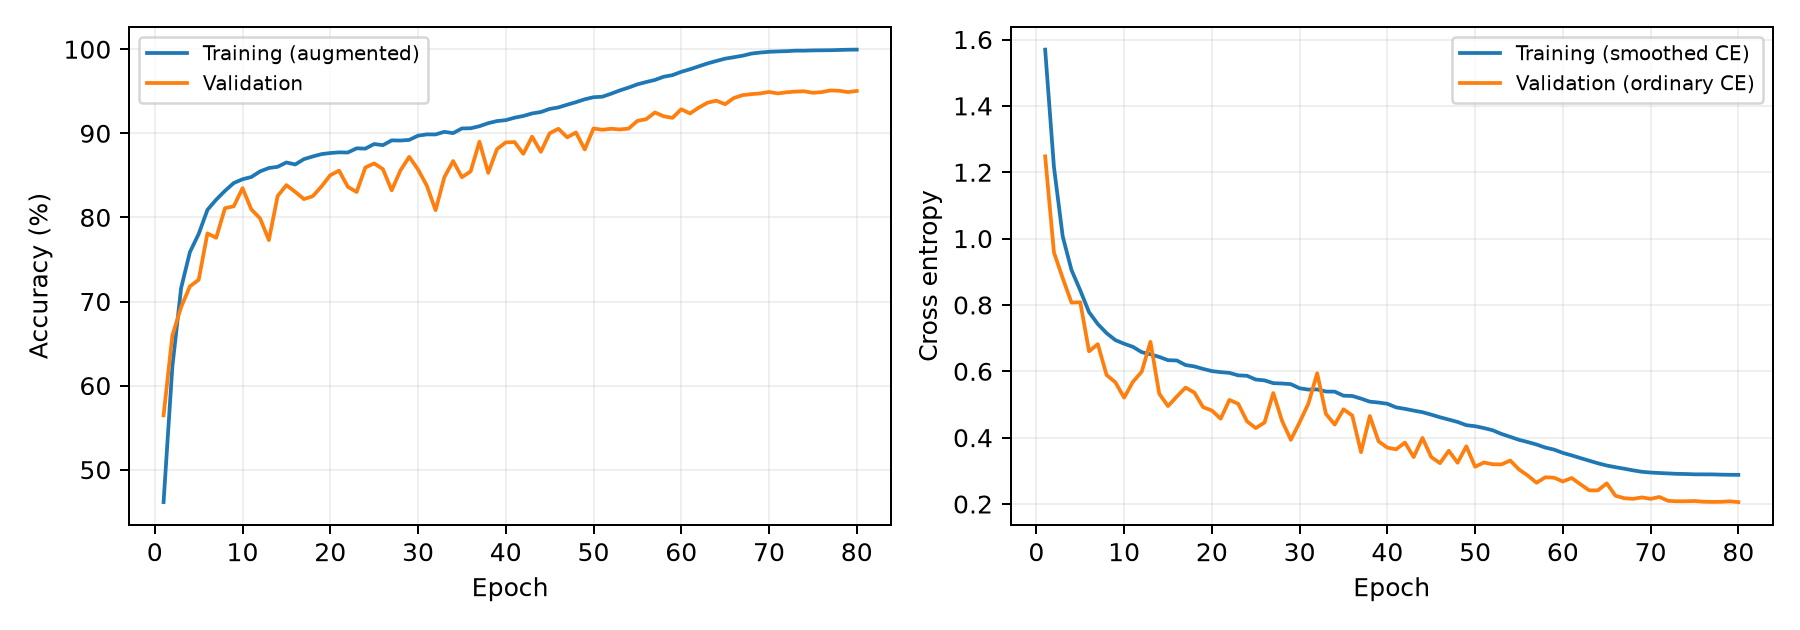

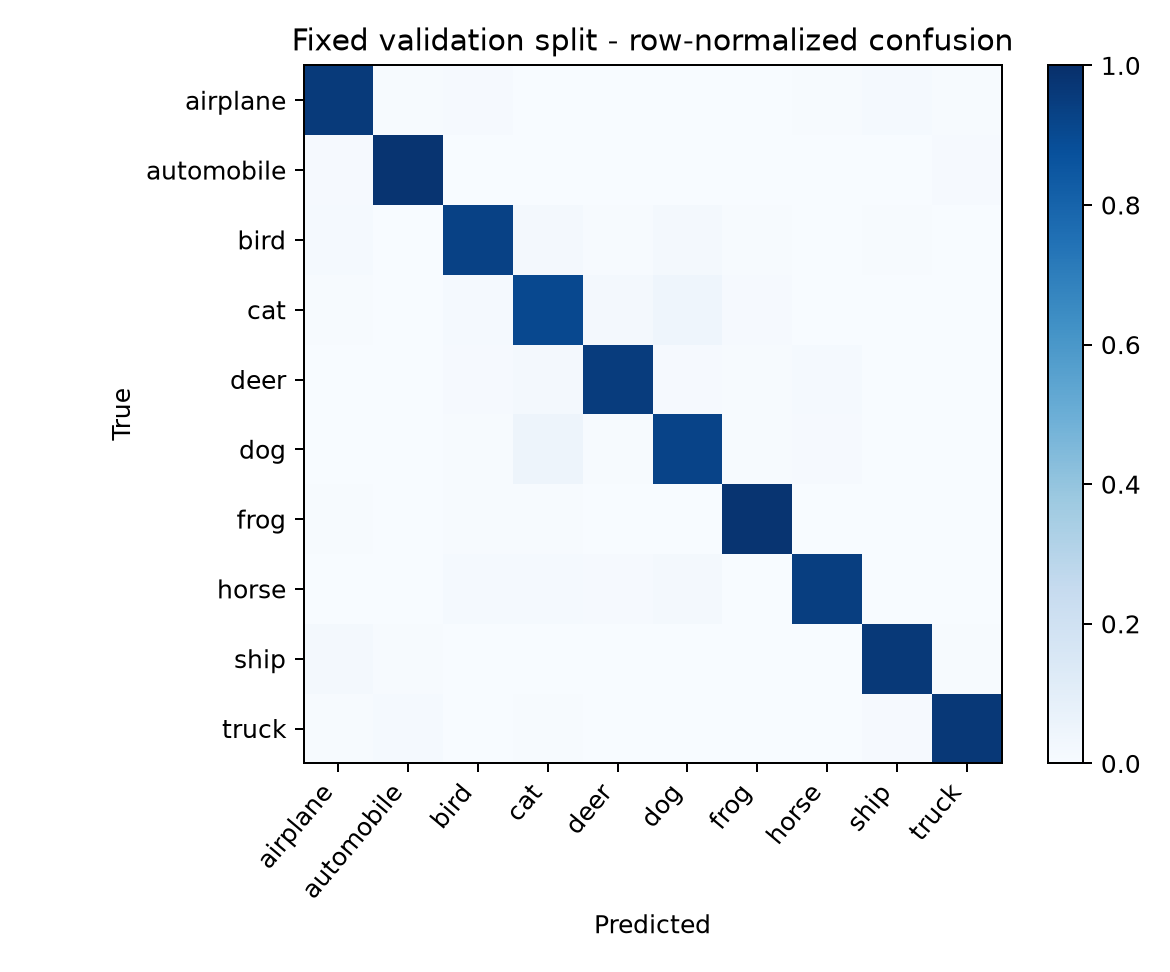

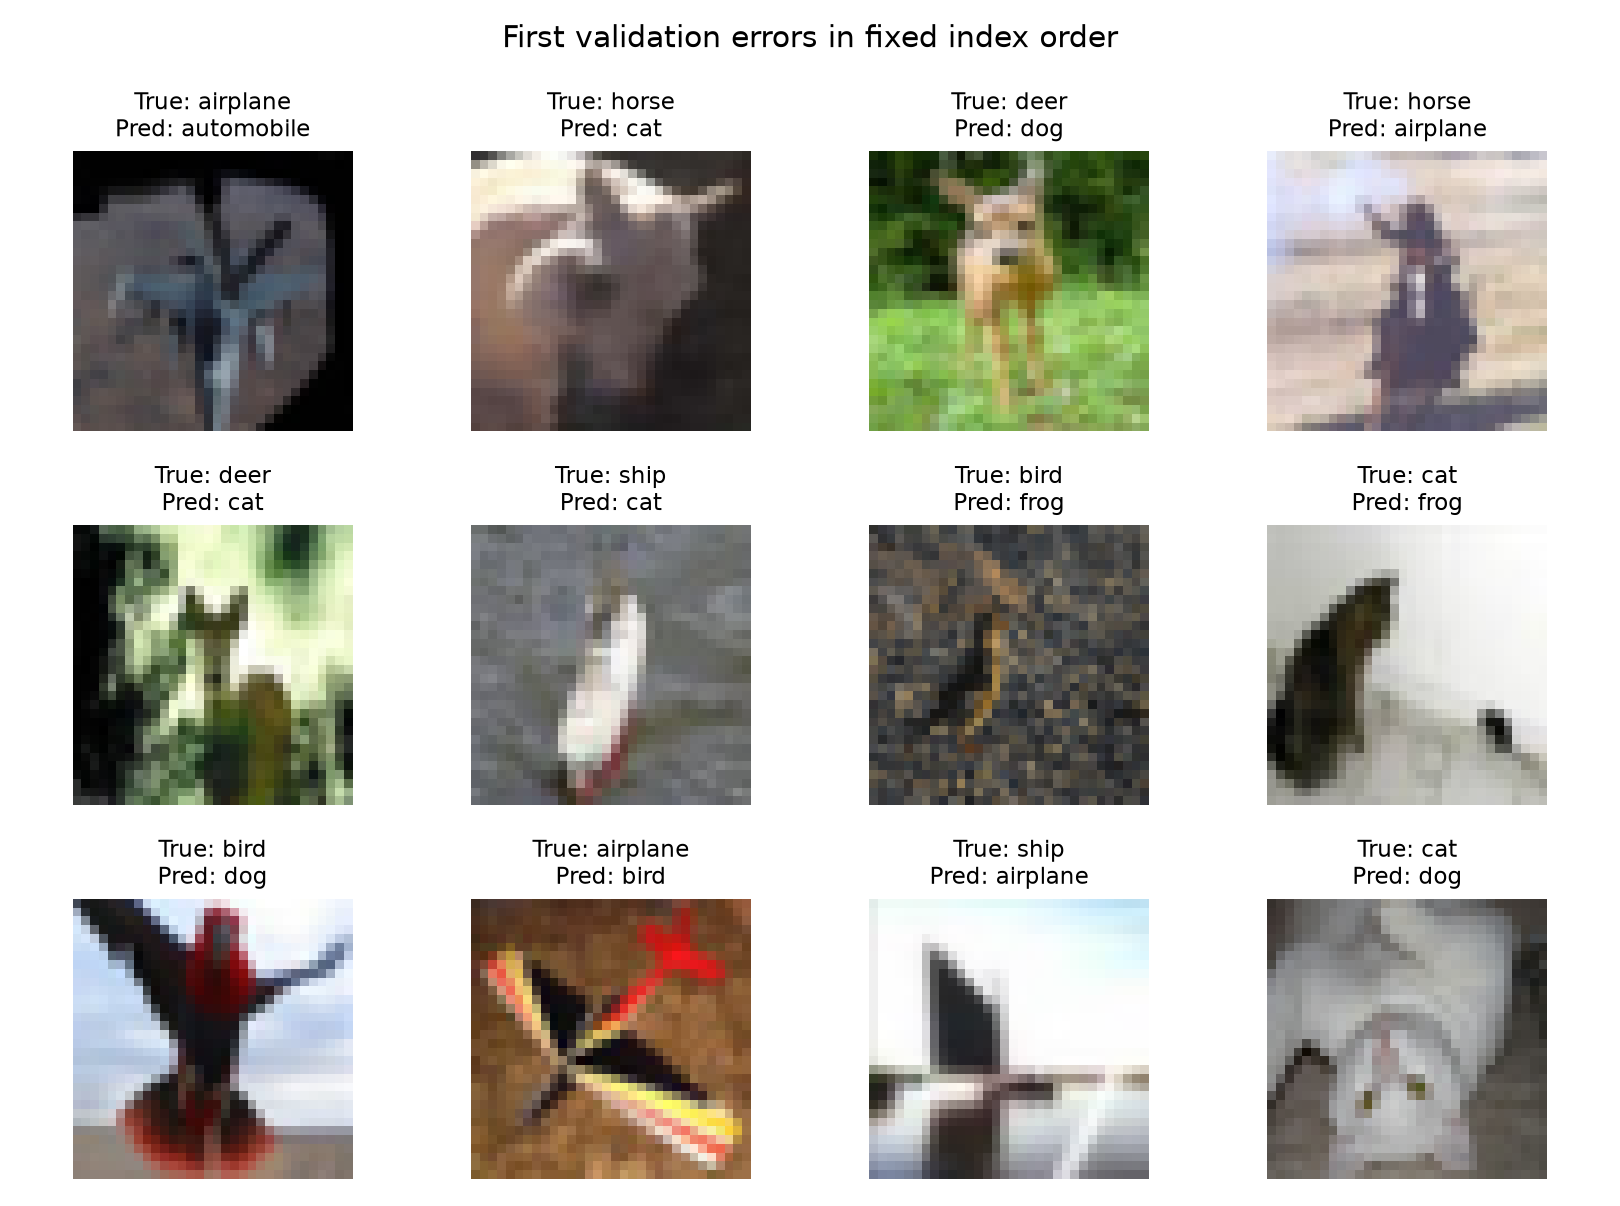

{
  "validation_count": 5000,
  "correct": 4755,
  "accuracy": 0.951,
  "wilson_95_interval_descriptive": [
    0.9446624814577625,
    0.9566450259581397
  ],
  "interval_caveat": "Checkpoint selected on this validation set; interval is descriptive, not an independent generalization guarantee.",
  "class_accuracy": {
    "airplane": 0.96,
    "automobile": 0.982,
    "bird": 0.932,
    "cat": 0.906,
    "deer": 0.95,
    "dog": 0.922,
    "frog": 0.982,
    "horse": 0.944,
    "ship": 0.964,
    "truck": 0.968
  },
  "hidden_test_score": null,
  "example_policy": "First12 errors in ascending fixed validation index; no hand selection"
}


In [4]:
# Real diagnostics generated from the selected checkpoint.
from IPython.display import display, Image
for name in ['learning_curves', 'confusion', 'errors']:
    display(Image(filename=str(ROOT/'results/main/figures'/f'{name}.png')))
print((ROOT/'results/main/diagnostics.json').read_text())

## Reproduce full training

```bash
python code/prepare_data.py /path/to/data.zip --out data
python code/train.py --epochs 80 --out results/main
python code/analyze.py --device mps
```

Run only inside an allocated GPU session when using NYU HPC; use Cloud Bursting, not a login node or the Torch cluster. Hardware and software differences can change floating-point results.

## Sources
- He et al. *Deep Residual Learning for Image Recognition*. CVPR, 2016. https://arxiv.org/abs/1512.03385
- Krizhevsky. *Learning Multiple Layers of Features from Tiny Images*. 2009. https://www.cs.toronto.edu/~kriz/cifar.html
- Instructor-linked background repository: https://github.com/kuangliu/pytorch-cifar
- Paszke et al. *PyTorch: An Imperative Style, High-Performance Deep Learning Library*. NeurIPS, 2019. https://arxiv.org/abs/1912.01703